In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
# !pip install imutils
import imutils

# Image I/O and channel structure
Load the input image and show its dimensions, keeping in mind that images are represented as a multi-dimensional NumPy array with shape $h\times w\times c$.
- $h$: height, the number of rows
- $w$: width, the number of columns
- $c$: channels, the number of channels/depth 

OpenCV stores images in BGR order rather than RGB so we swap the ordering of the channels, because `plt.imshow(image)` expects `image` to be in RGB order.
Try to see what happens if you display `bgr_img` instead of `image`.

In [2]:
# Load the image and inspect its structure.
# cv2.imread() reads pixel data in BGR channel order (an
# OpenCV convention), but matplotlib's plt.imshow() expects RGB order.
# Without converting, the colors would look wrong (e.g. blue and red
# swapped). We fix this by splitting the image into its individual
# channels and re-merging them in reversed (R, G, B) order.
# Every image loaded into OpenCV/numpy is just a
# 3D array of shape (height, width, channels). Printing these values is
# a quick sanity check on what we've loaded (image size and color depth)
# before doing any further processing.
bgr_img = cv2.imread("jp.png")
b,g,r = cv2.split(bgr_img)       # get b,g,r
image = cv2.merge([r,g,b])
(h, w, d) = image.shape
print("width={}, height={}, depth={}".format(w, h, d))

width=600, height=322, depth=3


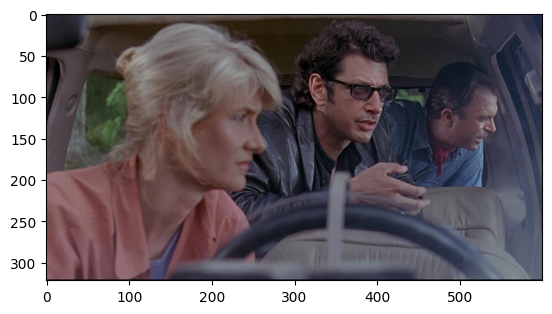

In [3]:
# Display the corrected RGB image.
plt.imshow(image)

# Data/Image indexing
Access the RGB pixel located at $x=50$, $y=100$

In [4]:
# Access a single pixel's color values directly.
# Since the image is just a numpy array, indexing into it with
# [row, column] (note: y first, then x; numpy indexes as
# [height_index, width_index]) returns that pixel's channel values
# directly, here as (R, G, B) since we already converted to RGB order.
(R, G, B) = image[100, 50]
print("R={}, G={}, B={}".format(R, G, B))

R=41, G=49, B=37


An image consists of multiple channels (3 in our case: red, green and blue).
We can split these up and then display each image:

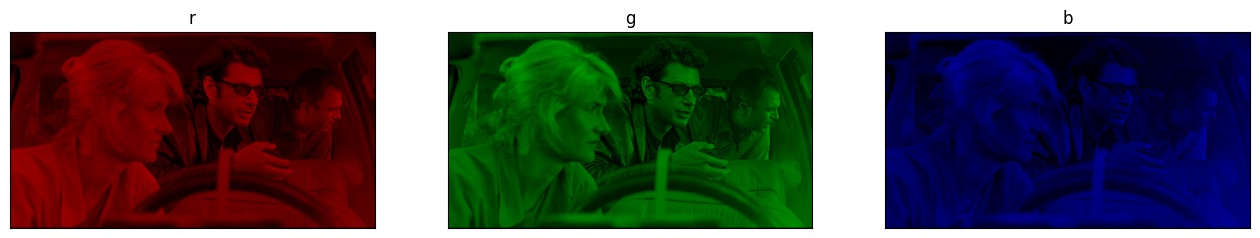

In [5]:
# Visualize each color channel (R, G, B) separately.
# Splitting an image into its individual channels helps build
# intuition for how color images are represented. Each channel captures
# only the contribution of that one color to the final image, and
# looking at them separately shows which regions are dominated by which color.
# For each channel index i, create a black image of the same shape
# as the original (np.zeros_like), then copy over only that one channel's
# values (channel[:,:,i] = image[:,:,i]) while leaving the other two
# channels at zero. This produces an image that displays only that
# channel's contribution in its true color rather than as grayscale.
# The three resulting images are plotted side by side using subplots for
# easy visual comparison; xticks/yticks are hidden to keep the plots
# clean.
titles=['r','g','b']
plt.figure(figsize = (16,4))
for i in range(3):
    channel = np.zeros_like(image)
    channel[:,:,i] = image[:,:,i]
    plt.subplot(1,3,i+1), plt.imshow(channel)
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()


Let's extract a $100\times 100$ pixel square ROI (Region of Interest) from the
input image starting at $x=320$,$y=60$ at ending at $x=420$,$y=160$

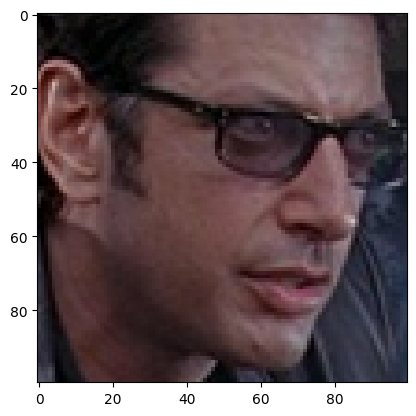

In [6]:
# Extract a rectangular Region of Interest (ROI) by array slicing.
# Since images are numpy arrays, cropping is just standard numpy
# slicing. This is a fundamental operation for isolating a specific
# part of an image for further processing.
# image[60:160, 320:420] slices rows 60 to 160 (the y/height range)
# and columns 320 to 420 (the x/width range). Remember that numpy
# indexes as [row, column], i.e. [y, x], which is the opposite order from
# how we usually write coordinates (x, y).
roi = image[60:160, 320:420]
plt.imshow(roi)

# Resizing operations
Let's resize the image to $200\times200$ px, ignoring the aspect ratio

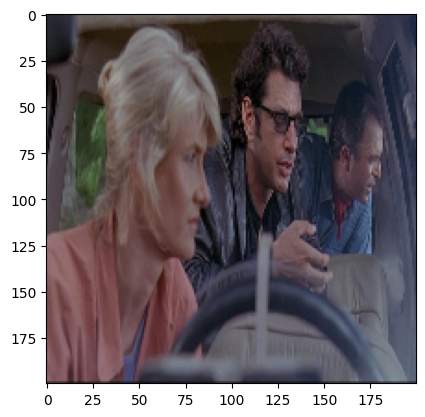

In [7]:
# Resize the image to a fixed 200x200 pixel size.
# Sometimes we need images to be an exact target size (e.g. as
# input to a fixed-size model) regardless of their original shape.
# cv2.resize(image, (width, height)) stretches/squishes the image
# to exactly fit the given dimensions, ignoring the original aspect
# ratio. So a non-square input image would come out visibly distorted.
resized = cv2.resize(image, (200, 200))
plt.imshow(resized)

Resizing to a fixed size will distort aspect ratio. So let's resize the width to be $w=300$ px, but we'll compute the new height based on the aspect ratio of the original image.

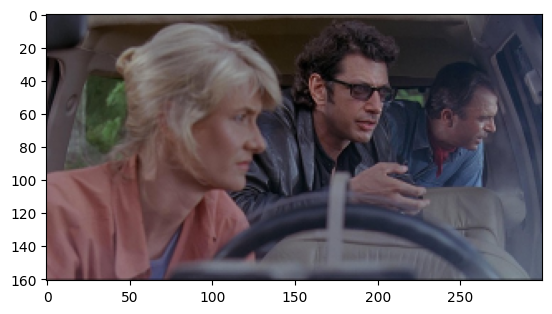

In [8]:
# Resize while preserving the original aspect ratio.
# To avoid the distortion seen in the previous cell, we fix the
# desired width (300 px) and manually compute the height that keeps the
# same width-to-height ratio as the original image, rather than just
# picking an arbitrary target size.
# r = new_width / original_width gives the scaling factor; applying
# that same factor to the original height (h * r) gives a proportionally
# scaled height, so the resized image looks like a scaled-down version of
# the original rather than a stretched one.
r = 300.0 / w
dim = (300, int(h * r))
resized = cv2.resize(image, dim)
plt.imshow(resized)

Manually computing the aspect ratio is tedious, so let's use the `imutils` library instead:

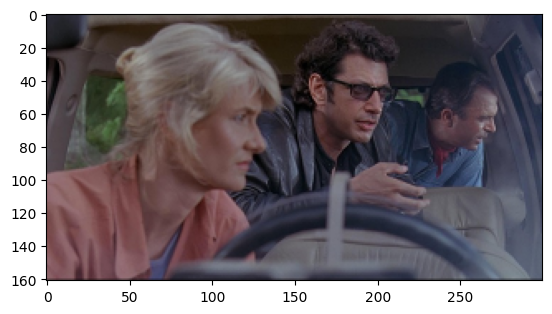

In [9]:
# Resize with a fixed width while preserving aspect ratio, using imutils.
# The previous cell's aspect-ratio math is correct but tedious to
# write out every time; imutils.resize() performs the exact same
# calculation internally, letting us just specify the desired width (or
# height) and have the other dimension computed automatically.
resized = imutils.resize(image, width=300)
plt.imshow(resized)

# Rotating operations
Let's rotate an image 45 degrees clockwise using OpenCV by first computing the image center, then constructing the rotation matrix, and then finally applying the affine warp:

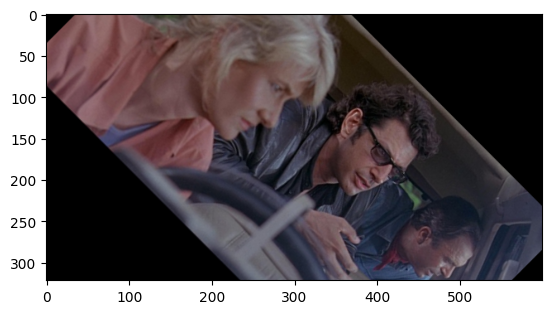

In [10]:
# Rotate the image manually using OpenCV's affine transform tools.
# Rotation in OpenCV isn't a single function call. It requires building
# a rotation matrix and then applying it as a geometric (affine) transformation,
# which is useful to understand even though imutils offers shortcuts below.
#   - 'center' is the pivot point for the rotation. Here the exact
#     center of the image, so it rotates in place rather than around a
#     corner.
#   - cv2.getRotationMatrix2D(center, angle, scale) builds a 2x3
#     transformation matrix for a rotation by 'angle' degrees around
#     'center', at the given 'scale' (1.0 = no resizing). A negative
#     angle (-45) rotates clockwise, since OpenCV's rotation convention
#     is counter-clockwise for positive angles.
#   - cv2.warpAffine(image, M, (w, h)) applies that transformation matrix
#     to the image, producing the rotated result. Note the output canvas
#     size is kept the same as the input (w, h), so corners of the
#     rotated image that fall outside this original frame get clipped.
center = (w // 2, h // 2)
M = cv2.getRotationMatrix2D(center, -45, 1.0)
rotated = cv2.warpAffine(image, M, (w, h))
plt.imshow(rotated)

Rotation can also be easily accomplished via `imutils` with less code:

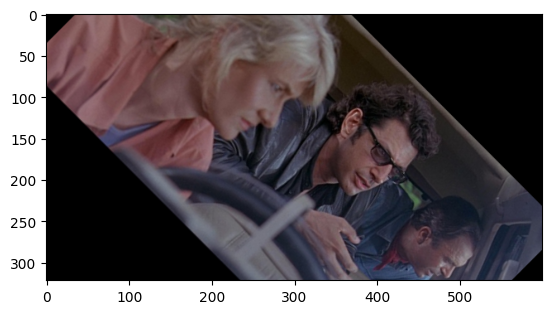

In [11]:
# Rotate the image using imutils, for the same clockwise 45-degree
# rotation as the manual approach above, but without needing to compute
# the center or build the rotation matrix ourselves.
# Like the manual cv2.warpAffine() version above, this still uses
# the original image dimensions as the output canvas size, so the
# rotated corners can still be clipped.
rotated = imutils.rotate(image, -45)
plt.imshow(rotated)

OpenCV doesn't "care" if our rotated image is clipped after rotation so we can instead use another imutils convenience function to help us out:

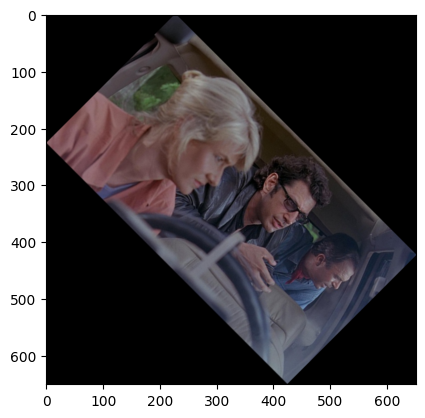

In [12]:
# Rotate the image without clipping the corners.
# Both rotation approaches above keep the output canvas the same
# size as the input image, which means the image's corners can get cut
# off once it's rotated (since a rotated square needs a larger bounding
# box to fully contain it). imutils.rotate_bound() instead automatically
# computes a larger output canvas sized to fit the entire rotated image,
# so nothing is lost.
rotated = imutils.rotate_bound(image, 45)
plt.imshow(rotated)

# Image blurring
Apply a Gaussian blur with a $11\times 11$ kernel to the image to smooth it. This is useful when you want to reduce high frequency noise.

Try playing around with the kernel size. What does that do?

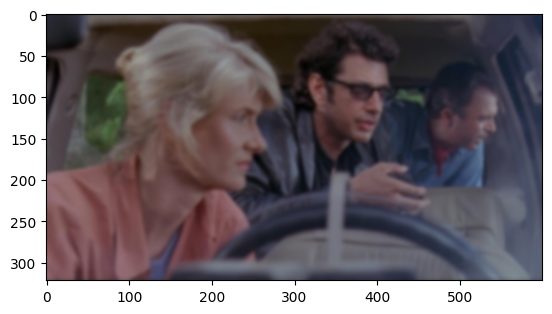

In [13]:
# Apply Gaussian blur to smooth the image.
# Blurring is commonly used to reduce high-frequency noise or fine
# detail before further processing (e.g. edge detection or thresholding
# tend to work better on a slightly smoothed image, since noise creates
# spurious sharp transitions).
# cv2.GaussianBlur(image, kernel_size, sigmaX) averages each pixel
# with its neighbors, weighted by a Gaussian (bell-curve) function;
# nearby pixels contribute more than distant ones. A larger kernel size
# (here 11x11, must be odd numbers) averages over a bigger neighborhood,
# producing a stronger blur. sigmaX=0 tells OpenCV to automatically
# compute an appropriate standard deviation for the Gaussian based on the
# kernel size, rather than specifying it manually.
kernel = (11,11)

blurred = cv2.GaussianBlur(image, kernel, 0)
plt.imshow(blurred)

# Drawing operations
Draw a 2 px thick red rectangle surrounding the face

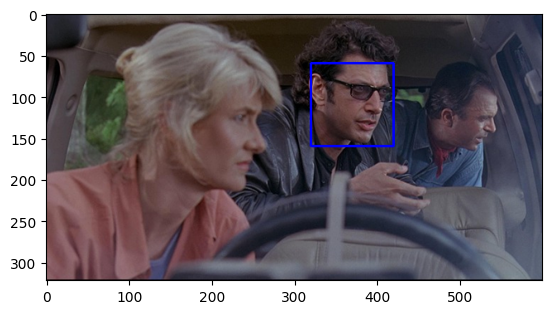

In [14]:
# Draw a rectangle outline on a copy of the image.
# cv2 drawing functions modify the image array in-place,
# so copying first (image.copy()) preserves the original,
# unmodified 'image' for use in later cells.
# cv2.rectangle(output, top_left, bottom_right, color, thickness)
# draws a rectangle from (320, 60) to (420, 160) in red ((0, 0, 255) in
# RGB-labeled order) with a 2-pixel-thick outline.
output = image.copy()
cv2.rectangle(output, (320, 60), (420, 160), (0, 0, 255), 2)
plt.imshow(output)

Draw a blue 20 px (filled in) circle on the image centered at $x=300$,$y=150$

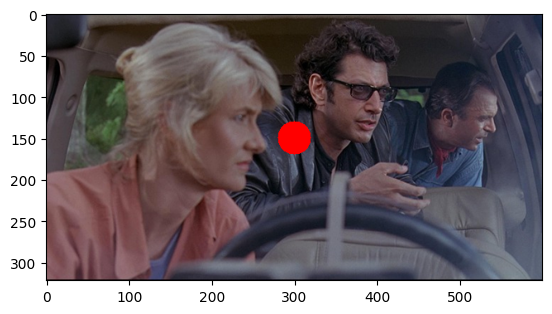

In [15]:
# Draw a filled circle on a copy of the image.
# cv2.circle(output, center, radius, color, thickness) draws a
# circle centered at (300, 150) with a 20-pixel radius, in blue
# ((255, 0, 0) in RGB-labeled order). Passing thickness=-1 is the
# convention OpenCV uses to fill the shape completely rather than just
# drawing its outline.
output = image.copy()
cv2.circle(output, (300, 150), 20, (255, 0, 0), -1)
plt.imshow(output)

Draw a 5 px thick red line from $x=60$,$y=20$ to $x=400$,$y=200$

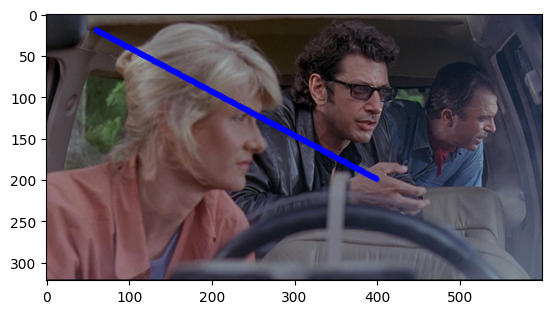

In [16]:
# Draw a straight line on a copy of the image.
# cv2.line(output, point1, point2, color, thickness) draws a
# 5-pixel-thick red line ((0, 0, 255) in RGB-labeled order) directly from
# the starting point (60, 20) to the ending point (400, 200).
output = image.copy()
cv2.line(output, (60, 20), (400, 200), (0, 0, 255), 5)
plt.imshow(output)

Draw green text on the image

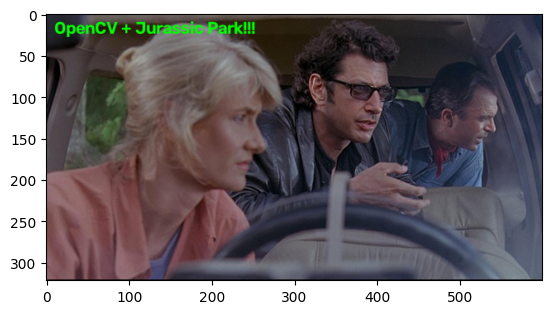

In [17]:
# Overlay text on a copy of the image.
# cv2.putText(output, text, origin, font, fontScale, color,
# thickness) draws the given string starting at pixel position (10, 25),
# using a simple built-in font (FONT_HERSHEY_SIMPLEX) at scale 0.7, in
# green ((0, 255, 0) in RGB-labeled order), with a stroke thickness of 2
# pixels. The origin point specifies the bottom-left corner of the text,
# following OpenCV's text-drawing convention.
output = image.copy()
cv2.putText(output, "OpenCV + Jurassic Park!!!", (10, 25),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
plt.imshow(output)

# Exercise 1 
Find a picture some picture and try to do the same on that image and play around with the parameters. 
Don't spend too much time here but remember some of the functions introduced here, continue with Exercice 2.